# Quickstart

The steady-state example, run from a copy of `examples/steady_state`: its input file loaded into a `Lucifer`, run, and its output shown.

In [1]:
from lucifer import Lucifer

In [2]:
L = Lucifer("lucifer.toml", threads=4)
L

input file,/private/tmp/lucifer_notebook_taw8oq7w/steady_state/lucifer.toml
path,not configured
state,not run
lattice,'../aramis.bmad'
run.out_root,'steady_state'
run.dump_beam_at,'UND##3'
run.dump_field_at,'UND##3'
beam.n_particle,8192
beam.bunch_charge,1.000692285594e-15
beam.sig_pz,8.804506566858e-05
beam.a_norm_emit,4e-07


The input file as Python, the keys it sets away from their defaults.

In [3]:
L.input

lattice,'../aramis.bmad'
run.out_root,'steady_state'
run.dump_beam_at,'UND##3'
run.dump_field_at,'UND##3'
beam.n_particle,8192
beam.bunch_charge,1.000692285594e-15
beam.sig_pz,8.804506566858e-05
beam.a_norm_emit,4e-07
beam.b_norm_emit,4e-07
field.lambda0,1e-10
field.grid_n_pts,256


## Run

In [4]:
L.run()

exit,0
out_root,steady_state
directory,/private/tmp/lucifer_ghjz7w9t
stats file,steady_state.stats.h5
files,"steady_state-final.beam.h5, steady_state-final.wf.h5, steady_state.stats.h5"


In [5]:
L.output.stats

file,steady_state.stats.h5
format,bmad-stats 1.0
records,1105
element ends,48
slices,1
s,0 to 57 m
components,x
harmonics,none


## Plot

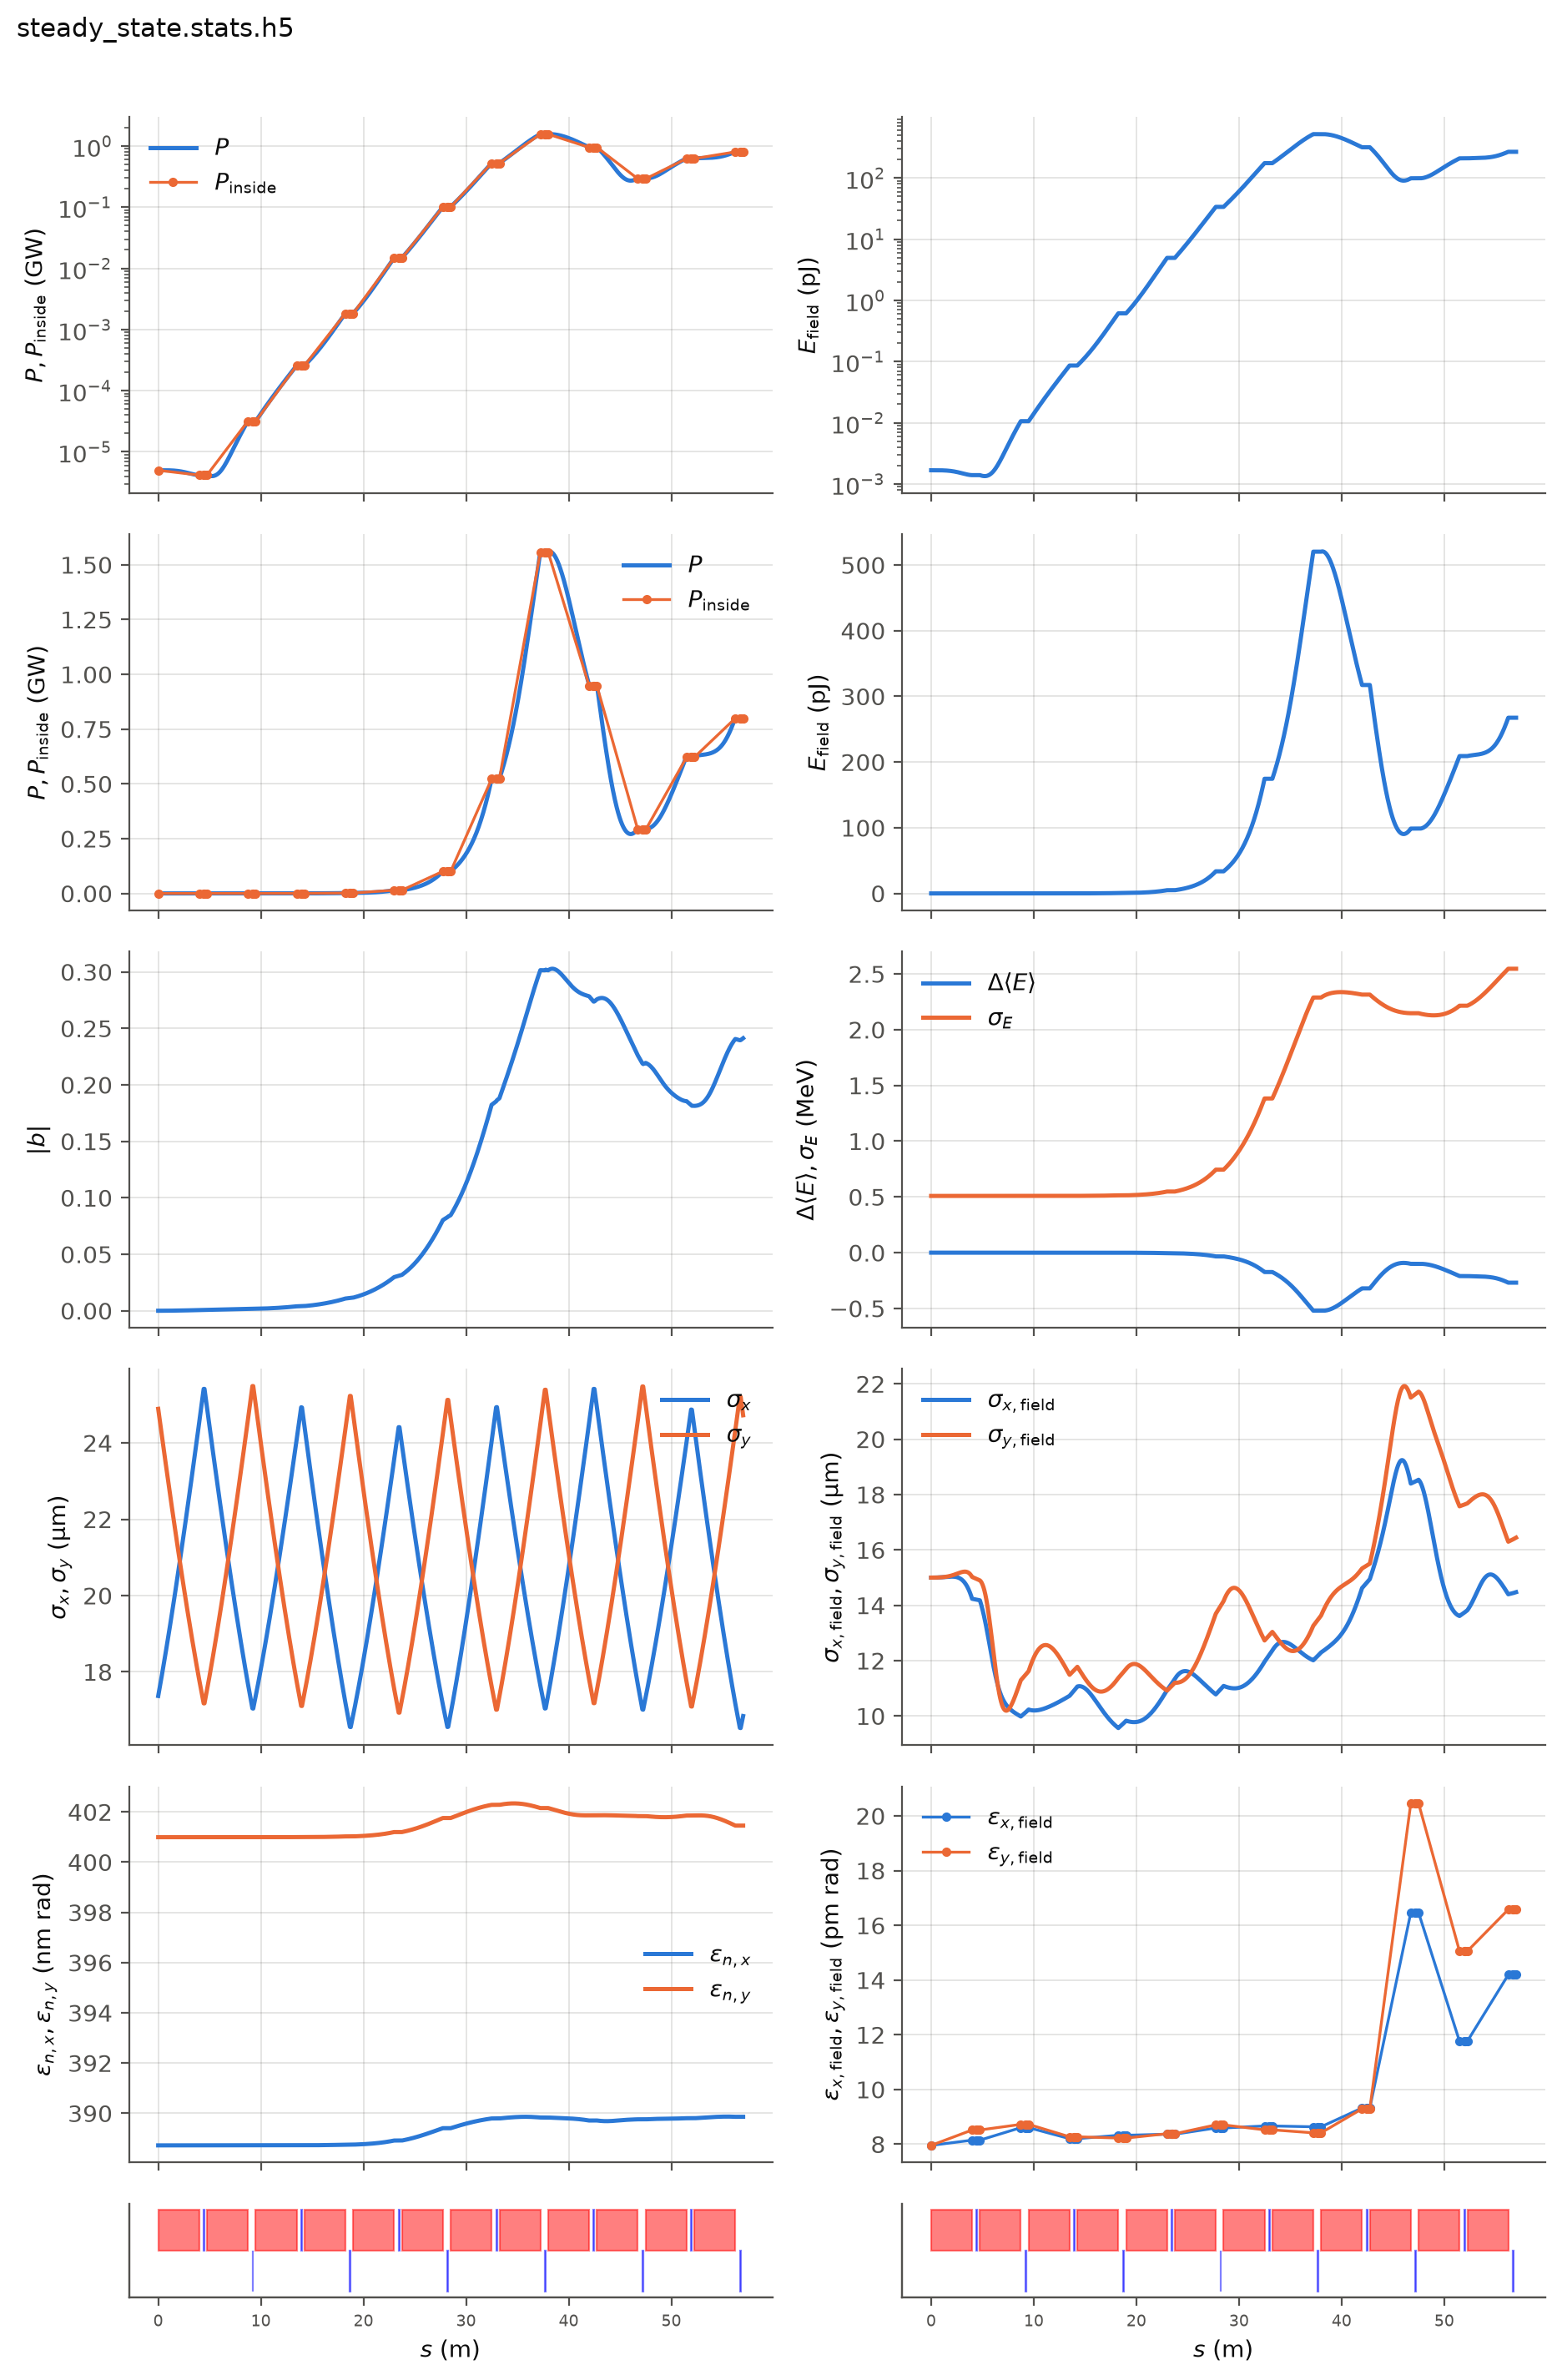

In [6]:
L.summary()

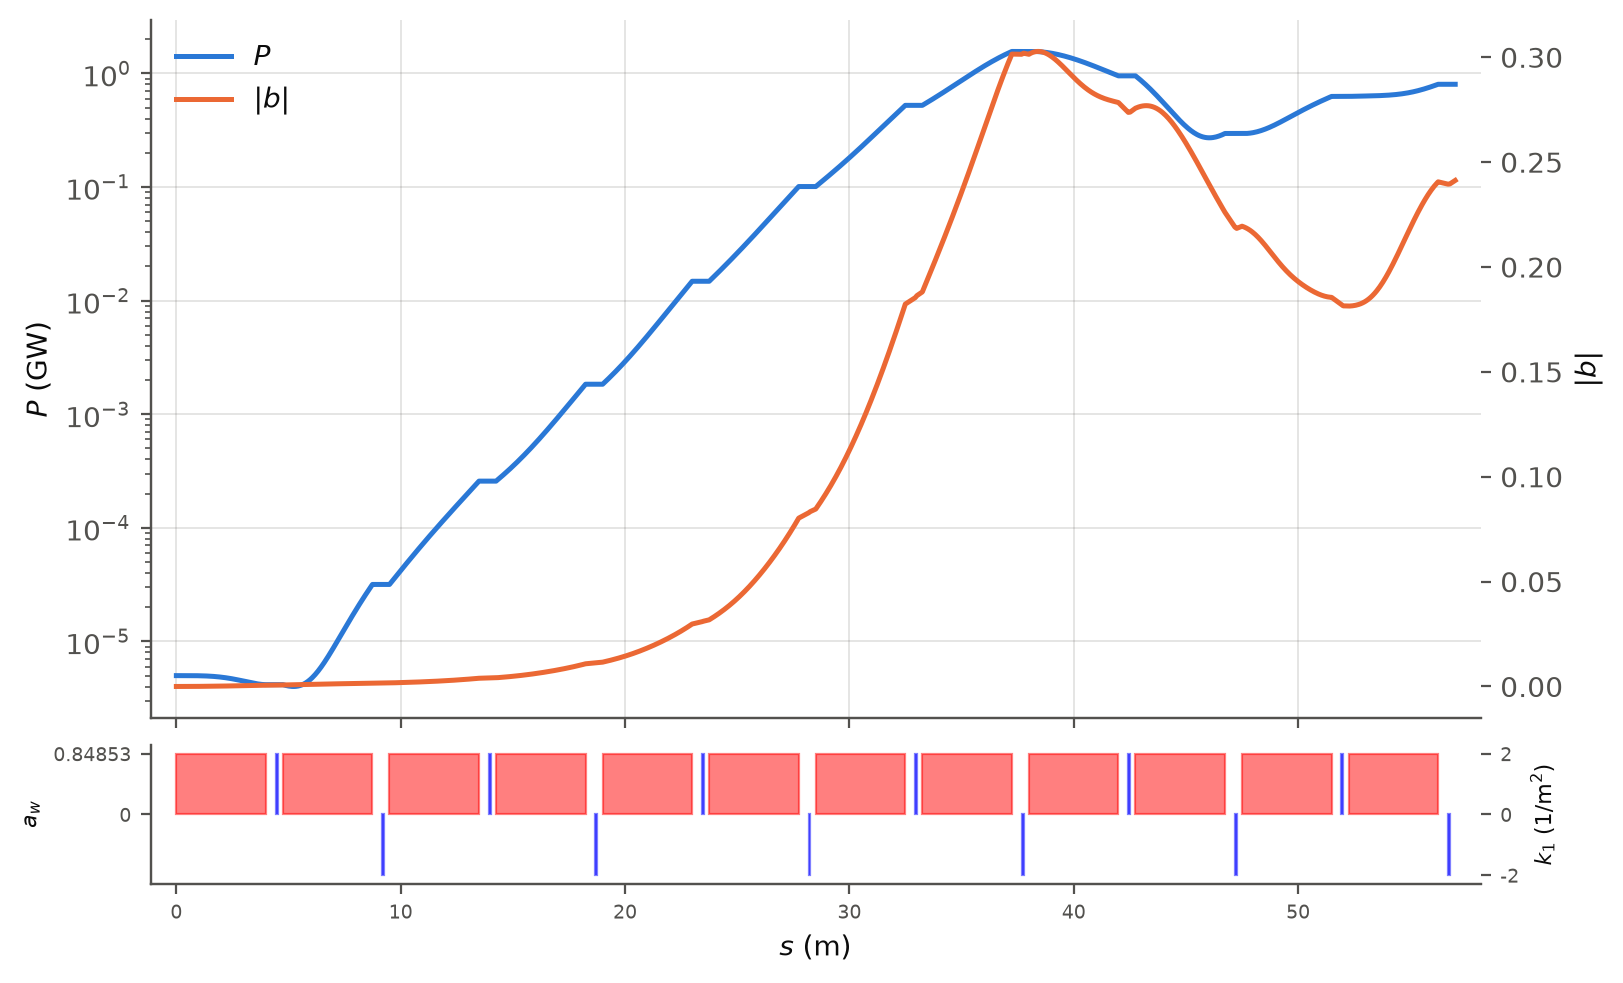

In [7]:
L.plot("field/total/power", y2="beam/slice/bunching", yscale="log")

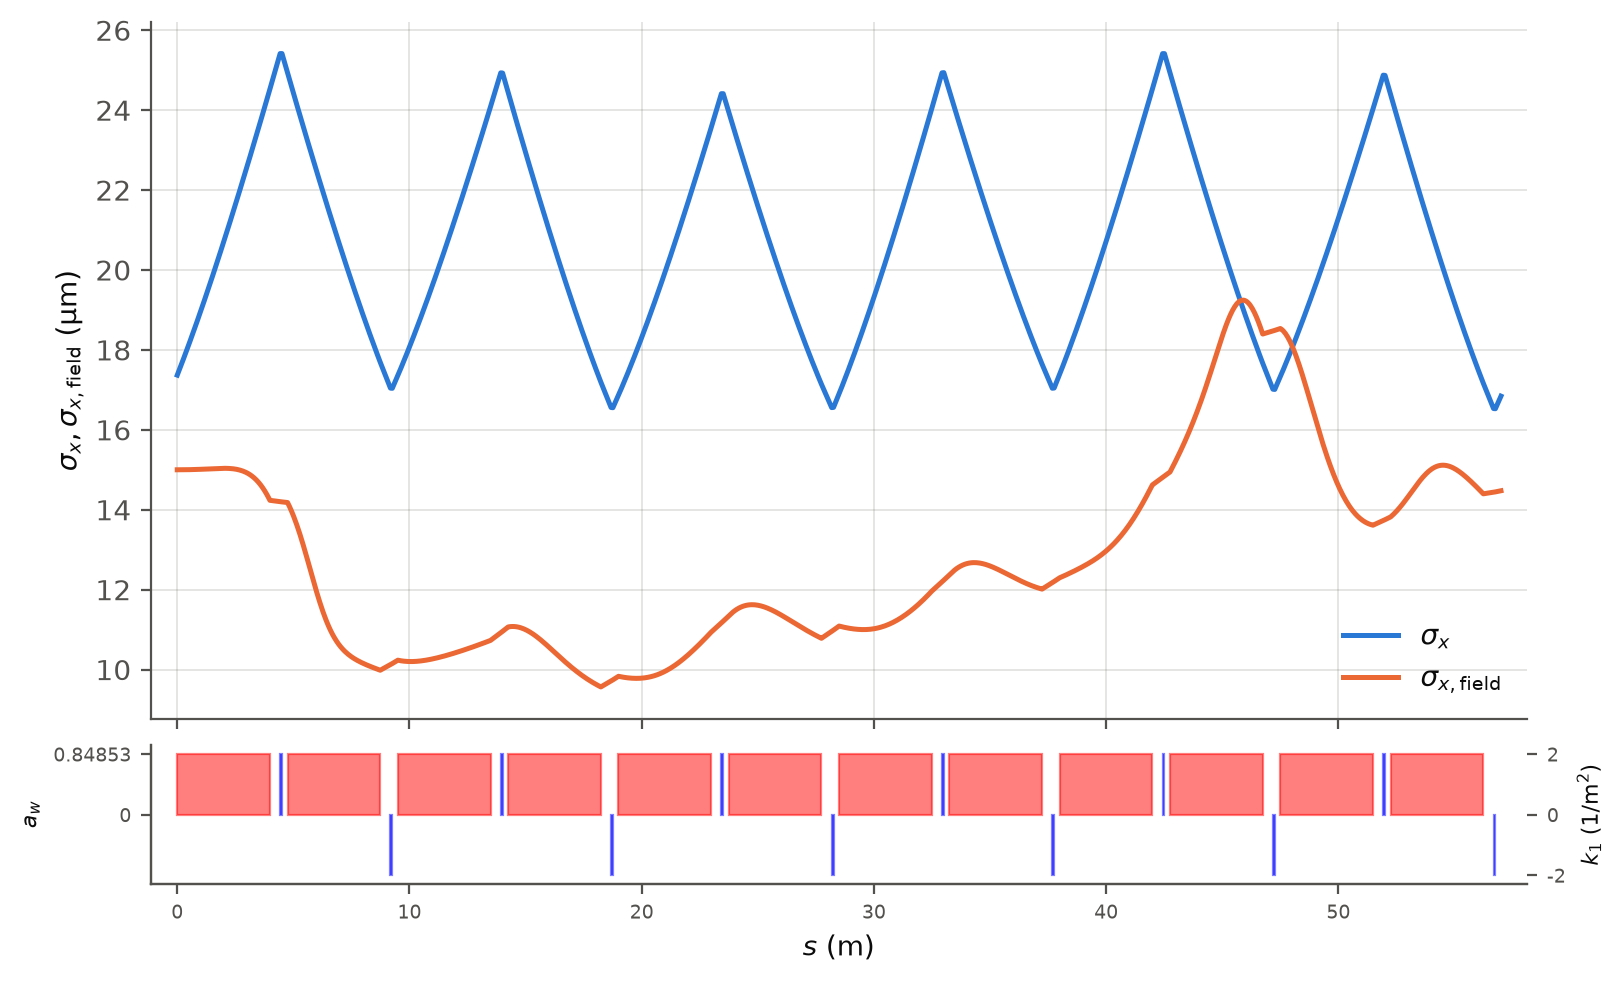

In [8]:
L.plot(["beam_size_x", "field_size_x"])

## Change a key and run again

The input file is written again before every run, so the run reads the key as it now stands.

In [9]:
L.input.field.seed_power *= 2
L.run()

exit,0
out_root,steady_state
directory,/private/tmp/lucifer_ghjz7w9t
stats file,steady_state.stats.h5
files,"steady_state-final.beam.h5, steady_state-final.wf.h5, steady_state.stats.h5"


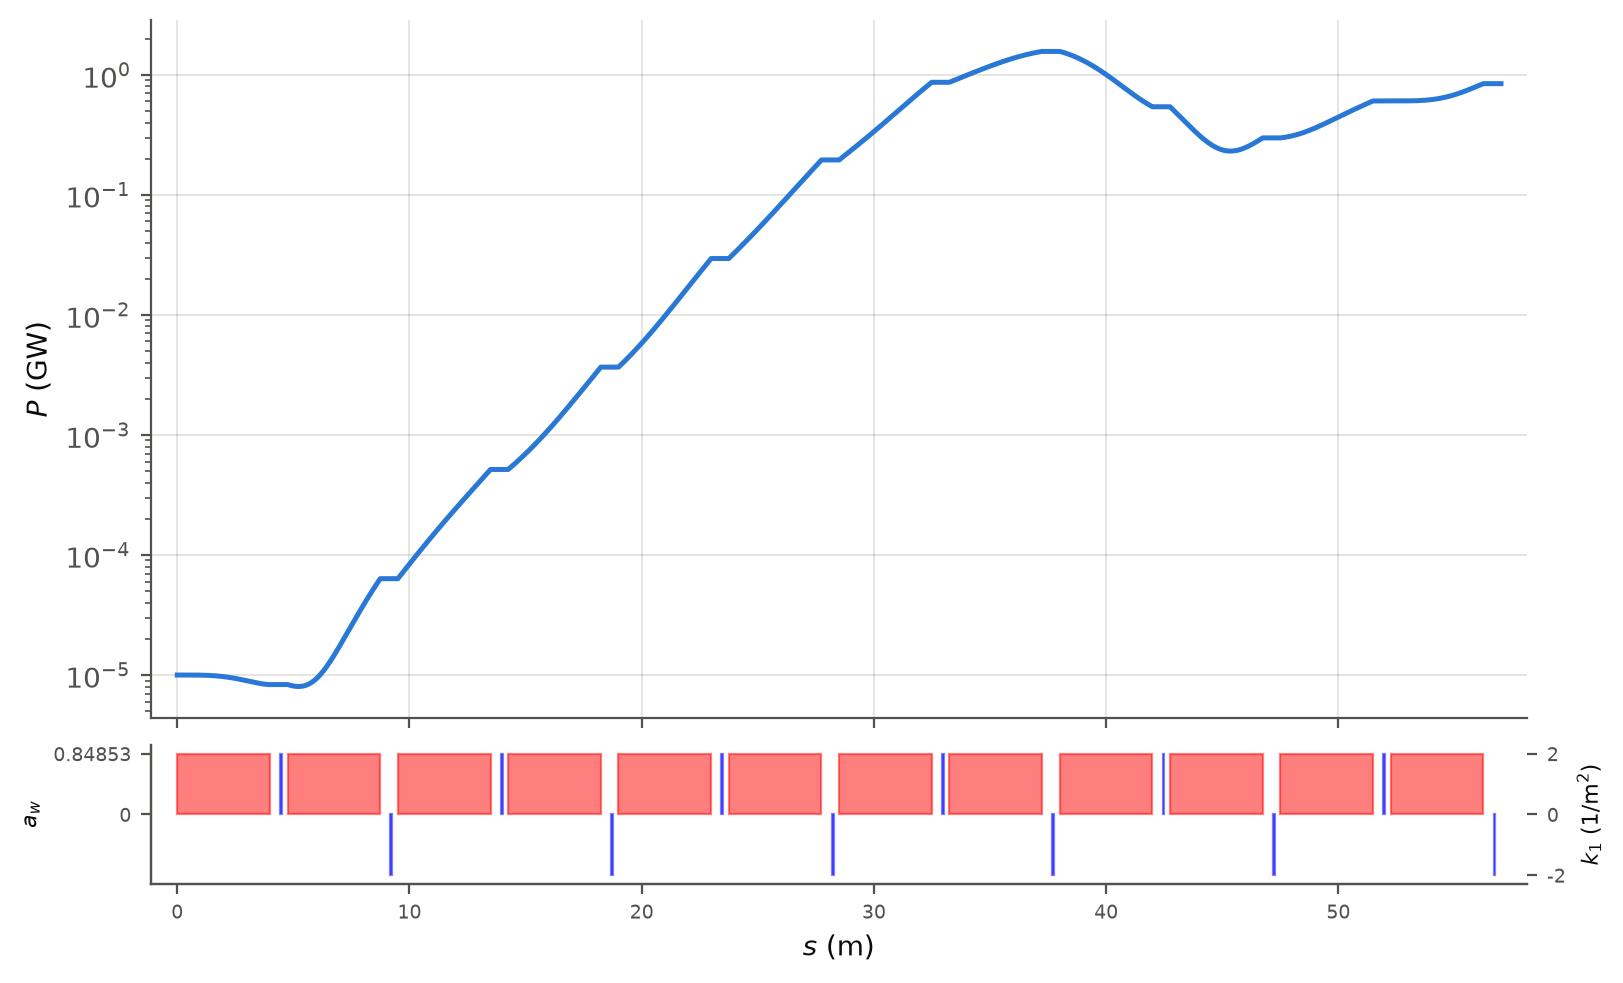

In [10]:
L.plot("field/total/power", yscale="log")

## Archive and restore

The archive is the stats file, which holds the input file the run read.

In [11]:
L.archive("steady_state.h5")

PosixPath('steady_state.h5')

In [12]:
R = Lucifer.from_archive("steady_state.h5")
R

archive,steady_state.h5
input file,in memory
path,not configured
state,finished
lattice,'/private/tmp/lucifer_notebook_taw8oq7w/aramis.bmad'
run.out_root,'steady_state'
run.dump_beam_at,['UND##3']
run.dump_field_at,['UND##3']
window.n_wavelength,1
beam.n_particle,8192
beam.bunch_charge,1.000692285594e-15


In [13]:
R.input.field.seed_power

10000.0